# 03 · Statistical Arbitrage in Indian Banks — Pairs Trading Without Look-Ahead

**Question:** Is there a tradable, market-neutral edge in mean-reverting bank-stock pairs?

The usual "HDFC Bank vs ICICI Bank" backtest estimates the hedge ratio on the *entire* sample and
then trades that same sample — the strategy knows the future. Here:

1. **Test the premise first:** is HDFC Bank / ICICI Bank actually cointegrated, and is it *stably*
   cointegrated? (Rolling Engle-Granger tests.)
2. **Kalman filter** hedge ratio that updates daily using only past prices.
3. A **systematic scanner** over all 78 pairs from 13 listed banks: every 6 months, select pairs on
   the past 12 months (cointegration p-value + mean-reversion half-life), then trade them on the
   *next* 6 months only.
4. Costs of 10 bps per leg per side (shorts implemented via single-stock futures — overnight
   shorting in the Indian cash market isn't possible).

In [1]:
import itertools
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src") if (Path.cwd().parent / "src").exists() else "src")

import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.tsa.stattools import coint

from nql import data, metrics
from nql.plotting import PALETTE, plt, save

COST = 0.0010
prices = data.panel(data.BANKS, start="2018-04-01").dropna()
logp = np.log(prices)
rets = prices.pct_change().fillna(0)
nifty_r = data.nifty().pct_change().reindex(prices.index).fillna(0)
rf = data.risk_free_daily(prices.index)
print(prices.shape, prices.index[0].date(), "→", prices.index[-1].date())

(2101, 13) 2018-04-02 → 2026-09-25


## 1 · Is HDFC Bank / ICICI Bank really cointegrated?

Rolling 1-year Engle-Granger test, stepped monthly. If the relationship were a stable law of
nature, the p-value would sit below 0.05 most of the time.

In [2]:
A, B = "hdfcbank", "icicibank"
roll_p = {}
for end in pd.date_range(prices.index[252], prices.index[-1], freq="ME"):
    w = logp.loc[:end].tail(252)
    roll_p[end] = coint(w[A], w[B])[1]
roll_p = pd.Series(roll_p)
full_p = coint(logp[A], logp[B])[1]
share_coint = float((roll_p < 0.05).mean())
print(f"Full-sample EG p-value: {full_p:.3f}; share of rolling 1y windows cointegrated: {share_coint:.0%}")

Full-sample EG p-value: 0.339; share of rolling 1y windows cointegrated: 12%


## 2 · Kalman-filter hedge ratio

State-space model: `log P_A = α_t + β_t · log P_B + ε_t`, with α, β following random walks. The
filter gives a hedge ratio that adapts as the banks' relative valuation drifts, using only
information up to each day.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


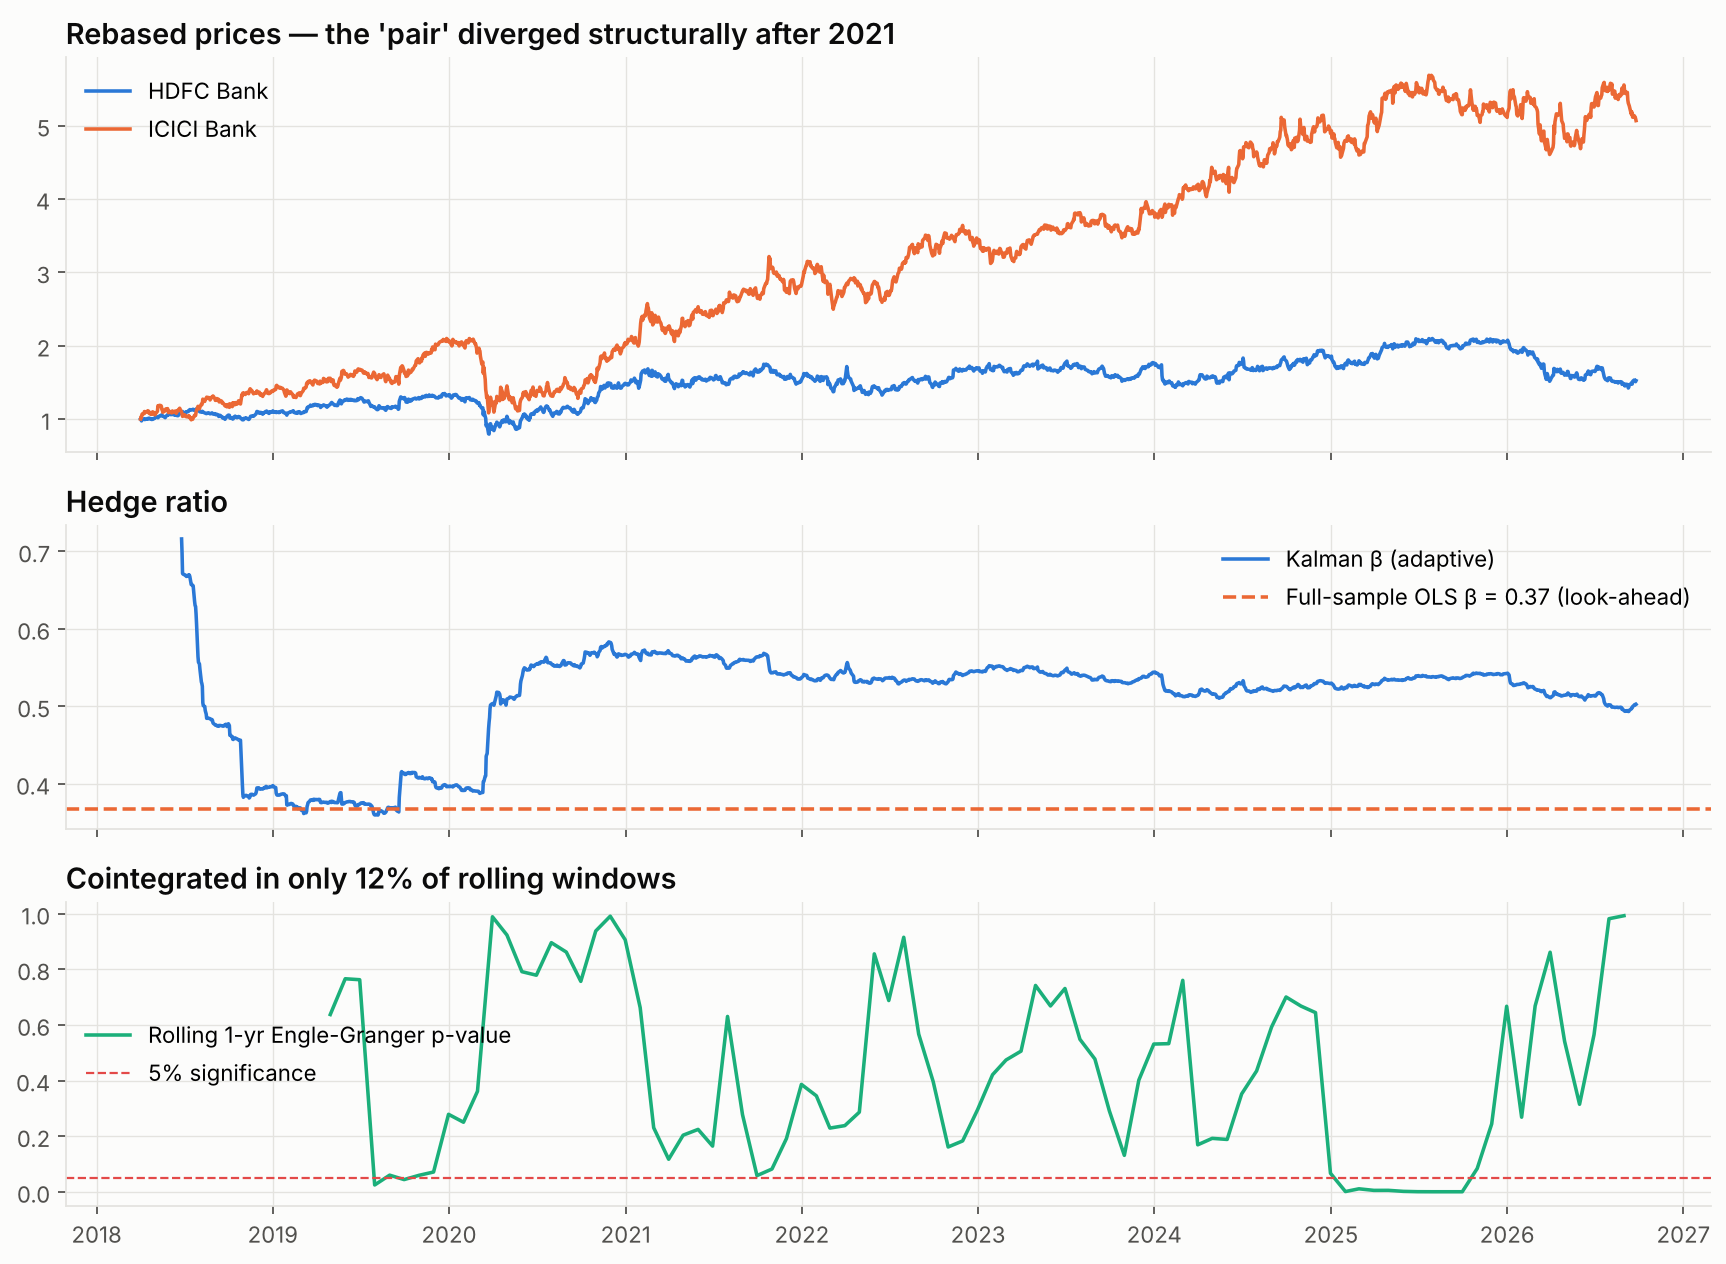

PosixPath('/home/claude/nse-quant-lab/reports/figures/03_hdfc_icici.png')

In [3]:
def kalman_beta(y: pd.Series, x: pd.Series, delta: float = 1e-5, obs_var: float = 1e-3):
    n = len(y)
    theta = np.zeros(2); P = np.eye(2)
    Q = delta / (1 - delta) * np.eye(2)
    betas, alphas, spread, spread_var = (np.zeros(n) for _ in range(4))
    for t in range(n):
        F = np.array([1.0, x.iloc[t]])
        P = P + Q                          # predict
        yhat = F @ theta
        S = F @ P @ F + obs_var
        e = y.iloc[t] - yhat               # innovation uses yesterday's state → no look-ahead
        spread[t], spread_var[t] = e, S
        K = P @ F / S
        theta = theta + K * e              # update
        P = P - np.outer(K, F) @ P
        alphas[t], betas[t] = theta
    return pd.DataFrame({"alpha": alphas, "beta": betas, "spread": spread, "z": spread / np.sqrt(spread_var)}, index=y.index)


kf = kalman_beta(logp[A], logp[B])
static_beta = sm.OLS(logp[A], sm.add_constant(logp[B])).fit().params[B]

fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True, gridspec_kw={"height_ratios": [1.3, 1, 1]})
axes[0].plot(prices.index, prices[A] / prices[A].iloc[0], color=PALETTE[0], label="HDFC Bank")
axes[0].plot(prices.index, prices[B] / prices[B].iloc[0], color=PALETTE[1], label="ICICI Bank")
axes[0].set_title("Rebased prices — the 'pair' diverged structurally after 2021"); axes[0].legend()
axes[1].plot(kf.index[60:], kf.beta[60:], color=PALETTE[0], label="Kalman β (adaptive)")
axes[1].axhline(static_beta, color=PALETTE[1], ls="--", label=f"Full-sample OLS β = {static_beta:.2f} (look-ahead)")
axes[1].set_title("Hedge ratio"); axes[1].legend()
axes[2].plot(roll_p.index, roll_p, color=PALETTE[2], label="Rolling 1-yr Engle-Granger p-value")
axes[2].axhline(0.05, color="#e34948", ls="--", lw=1, label="5% significance")
axes[2].set_title(f"Cointegrated in only {share_coint:.0%} of rolling windows"); axes[2].legend()
save(fig, "03_hdfc_icici")

## 3 · Systematic pair scanner with rolling out-of-sample trading

**Formation (252 days):** for each of the 78 pairs, run Engle-Granger on log prices, estimate hedge
ratio β by OLS and the spread's mean-reversion **half-life** via an AR(1) fit. Keep pairs with
p < 0.05 and 5 ≤ half-life ≤ 40 days; take the 5 lowest p-values.

**Trading (next 126 days):** z-score the spread with the *formation* mean/std. Enter at |z| > 2,
exit at |z| < 0.5, stop-loss at |z| > 4 or when the window ends. Equal capital per pair slot.

In [4]:
FORM, TRADE, TOP = 252, 126, 5
ENTRY, EXIT, STOP = 2.0, 0.5, 4.0
pairs = list(itertools.combinations(data.BANKS, 2))


def half_life(spread: pd.Series) -> float:
    lag = spread.shift(1).dropna(); d = spread.diff().dropna()
    b = sm.OLS(d, sm.add_constant(lag)).fit().params.iloc[1]
    return -np.log(2) / b if b < 0 else np.inf


def trade_pair(a, b, beta, mu, sd, window, cost=COST):
    lp = logp.loc[window]
    z = ((lp[a] - beta * lp[b]) - mu) / sd
    pos = np.zeros(len(z)); cur = 0
    for i, zz in enumerate(z.values):
        if cur == 0:
            if zz > ENTRY: cur = -1
            elif zz < -ENTRY: cur = 1
        elif abs(zz) < EXIT or abs(zz) > STOP:
            cur = 0
        pos[i] = cur
    pos = pd.Series(pos, index=z.index)
    pos.iloc[-1] = 0  # flat at window end
    wa, wb = 1 / (1 + abs(beta)), -beta / (1 + abs(beta))
    held = pos.shift(1).fillna(0)
    r = held * (wa * rets.loc[window, a] + wb * rets.loc[window, b])
    turn = held.diff().abs().fillna(held.abs()) * (abs(wa) + abs(wb))
    return r - turn * cost, int((pos.diff().abs() > 0).sum() / 2)


idx = prices.index
selections = []  # (trade window, chosen pairs) - selection uses formation data only
for start in range(FORM, len(idx) - 5, TRADE):
    form = idx[start - FORM:start]; trade = idx[start:start + TRADE]
    cands = []
    for a, b in pairs:
        y, x = logp.loc[form, a], logp.loc[form, b]
        p = coint(y, x)[1]
        if p > 0.05:
            continue
        ols = sm.OLS(y, sm.add_constant(x)).fit()
        sp = y - ols.params.iloc[1] * x
        hl = half_life(sp)
        if 5 <= hl <= 40:
            cands.append((p, a, b, ols.params.iloc[1], sp.mean(), sp.std(), hl))
    cands.sort()
    selections.append((trade, cands[:TOP]))


def run_scanner(cost: float):
    book, rows = [], []
    for trade, chosen_ in selections:
        period = pd.Series(0.0, index=trade)
        for p, a, b, beta, mu, sd, hl in chosen_:
            r, n_trades = trade_pair(a, b, beta, mu, sd, trade, cost)
            period += r / TOP  # each slot gets 1/TOP of capital; empty slots sit in cash
            rows.append({"period_start": trade[0].date(), "pair": f"{a}/{b}", "p_value": p, "beta": beta,
                         "half_life": hl, "trades": n_trades, "pnl": float((1 + r).prod() - 1)})
        period += (TOP - len(chosen_)) / TOP * rf.loc[trade]
        book.append(period)
    return pd.concat(book), pd.DataFrame(rows)


strat, trade_log = run_scanner(COST)
bench = nifty_r.loc[strat.index]; rf_s = rf.loc[strat.index]
res = [metrics.summary(bench, rf_s, name="NIFTY 50"), metrics.summary(strat, rf_s, bench, name="Bank pairs scanner (OOS)")]
metrics.table(res)[["cagr", "vol", "sharpe", "max_dd", "beta", "corr", "alpha_ann", "alpha_t"]]

,cagr,vol,sharpe,max_dd,beta,corr,alpha_ann,alpha_t
name,,,,,,,,
NIFTY 50,9.9%,17.5%,0.34,-38.4%,nan,nan,nan%,nan
Bank pairs scanner (OOS),-2.7%,9.1%,-0.82,-23.7%,0.06,0.12,-7.8%,-2.32


In [5]:
pair_stats = {"pairs_selected": len(trade_log), "periods": len(selections),
              "win_rate_pairs": float((trade_log.pnl > 0).mean()), "avg_pair_pnl": float(trade_log.pnl.mean()),
              "most_frequent_pairs": trade_log.pair.value_counts().head(5).to_dict(),
              "hdfc_icici_full_sample_p": full_p, "hdfc_icici_share_windows_cointegrated": share_coint,
              "hdfc_icici_selected_count": int((trade_log.pair == f"{A}/{B}").sum())}
pd.Series(pair_stats)

pairs_selected                                                                          59
periods                                                                                 15
win_rate_pairs                                                                    0.474576
avg_pair_pnl                                                                     -0.022288
most_frequent_pairs                      {'bankbaroda/canbk': 4, 'federalbnk/canbk': 3,...
hdfc_icici_full_sample_p                                                          0.338826
hdfc_icici_share_windows_cointegrated                                             0.123596
hdfc_icici_selected_count                                                                1
dtype: object

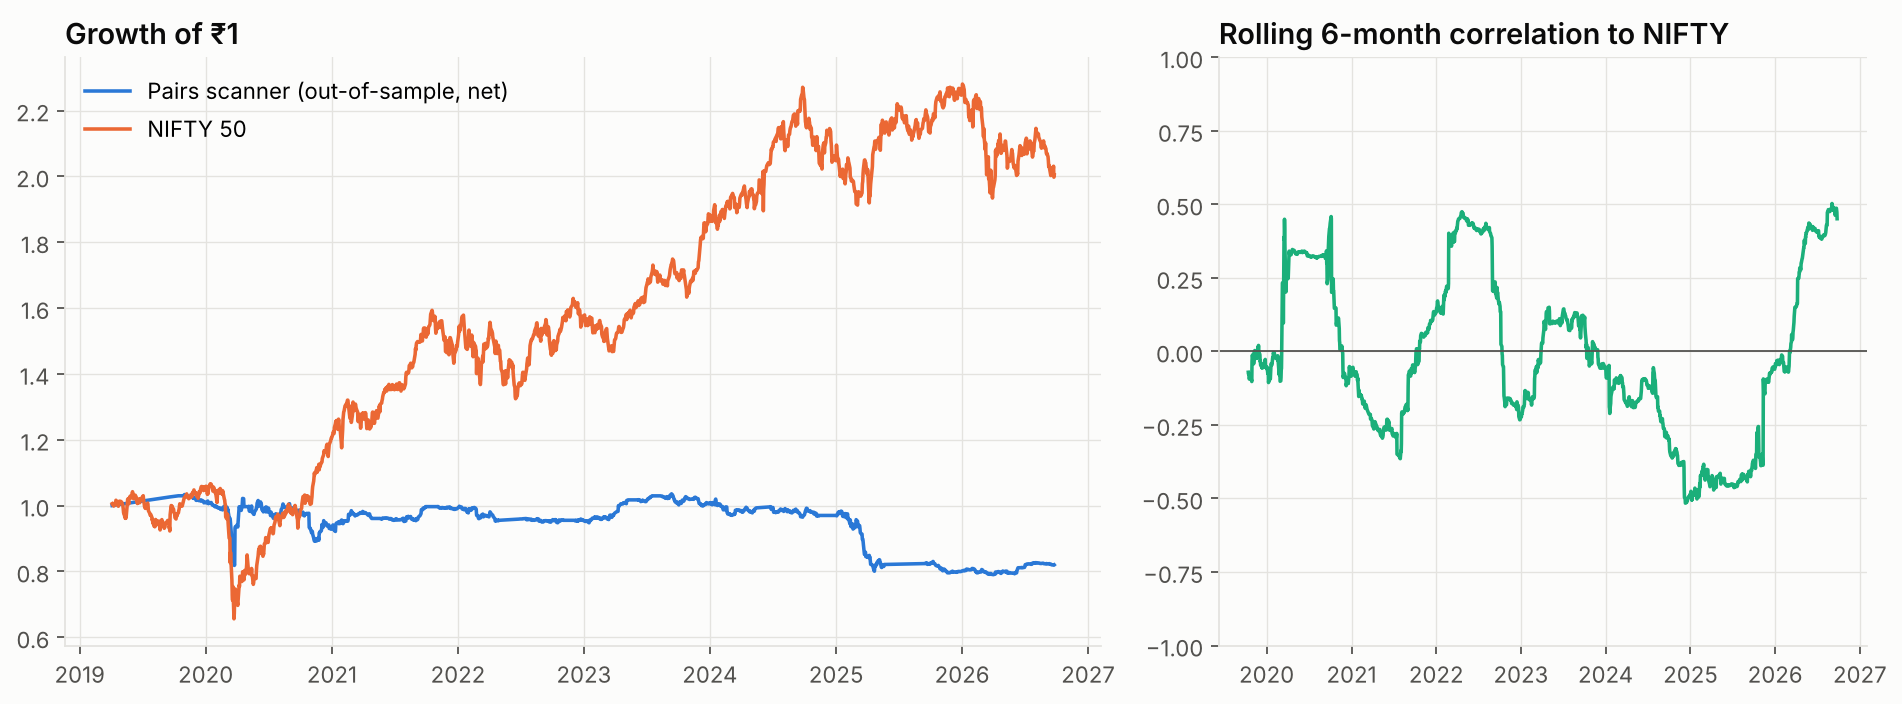

PosixPath('/home/claude/nse-quant-lab/reports/figures/03_pairs_performance.png')

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1.6, 1]})
axes[0].plot(strat.index, (1 + strat).cumprod(), color=PALETTE[0], label="Pairs scanner (out-of-sample, net)")
axes[0].plot(bench.index, (1 + bench).cumprod(), color=PALETTE[1], label="NIFTY 50")
axes[0].set_title("Growth of ₹1"); axes[0].legend()
roll_corr = strat.rolling(126).corr(bench)
axes[1].plot(roll_corr.index, roll_corr, color=PALETTE[2]); axes[1].axhline(0, color="#52514e", lw=0.8)
axes[1].set_title("Rolling 6-month correlation to NIFTY"); axes[1].set_ylim(-1, 1)
save(fig, "03_pairs_performance")

## 4 · Is it the costs? Sensitivity to transaction costs

In [7]:
cost_rows = []
for c in [0.0, 0.0005, 0.0010, 0.0020]:
    sr_, _ = run_scanner(c)
    cost_rows.append({"cost_bps_per_side": c * 1e4, "cagr": metrics.cagr(sr_), "sharpe": metrics.sharpe(sr_, rf.loc[sr_.index])})
cost_tab = pd.DataFrame(cost_rows).set_index("cost_bps_per_side")
cost_tab.round(3)

,cagr,sharpe
cost_bps_per_side,,
0.0,0.014,-0.369
5.0,-0.007,-0.595
10.0,-0.027,-0.821
20.0,-0.066,-1.272


## Takeaways

* **The premise fails.** HDFC Bank / ICICI Bank is *not* cointegrated over 2018-2026 (Engle-Granger
  p ≈ 0.34) and passes the test in only ~12% of rolling 1-year windows. The two banks diverged
  structurally (HDFC-HDFC Ltd merger in Jul-2023, ICICI's re-rating), so a static full-sample hedge
  ratio quietly bakes in hindsight.
* **Run honestly, out-of-sample, the bank pairs scanner loses money**: ≈ −2.7% CAGR net of 10 bps
  costs (Sharpe ≈ −0.8) across 15 six-month windows and 59 selected pairs, with a 47% pair win rate.
  It *is* market-neutral (β ≈ 0.06), but neutral-and-negative is not alpha.
* **Costs aren't the whole story** — even at zero cost it earned ~1.4% a year, below the overnight
  rate. Cointegration found in a 12-month window mostly did not persist into the next six months.
* What would be needed for a real edge: intraday data (faster mean reversion), a fundamental reason
  for the pair to co-move (e.g. holding-company vs subsidiary, dual listings, ETF vs basket), and
  regime filters. That is the honest research agenda — not a bigger parameter search.

In [8]:
data.save_results("03_pairs", {"performance": res, "stats": pair_stats, "cost_sensitivity": cost_tab.reset_index().to_dict(orient="records"),
                               "trade_log": trade_log.assign(period_start=trade_log.period_start.astype(str)).to_dict(orient="records")})
print("saved")

saved
